# Right-censored data: the HAL point estimators

With right-censored data we observe `T`, the smaller of the event time and the censoring time, and `Delta`,
which is 1 when the event was observed. `fit_right_censored` estimates the event-time density with HAL and
reports its survival at chosen time points. Its four methods share Stage 1, an IPCW-weighted HAL-MLE whose L1
bound M1 is chosen by cross-validation; the default, `"cvl1mle"`, then maximizes the observed-data likelihood
with the bound chosen by cross-validation over [M1, 2 M1].

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta

from haldensity.datasets import make_right_censored
from haldensity.rc import METHODS, fit_right_censored

data = make_right_censored(400, seed=1)          # event times Beta(2.2, 2.5); censoring Unif[0, 1.2]
truth = beta(2.2, 2.5)
print(f"{data['Delta'].mean():.0%} of the event times are observed")
data.head()

60% of the event times are observed


,T,Delta
0,0.469369,1
1,0.262370,0
2,0.521823,1
3,0.053164,0
4,0.614091,1


In the summary, `survival` and `density` are the fit's values at each time point `t0`, `norm_constraint` is the
L1 bound of the fit used there and `norm_factor` is that bound divided by M1.

In [2]:
points = np.array([0.2, 0.4, 0.6, 0.8])
est = fit_right_censored(data, points, method="cvl1mle", n_trials=20, random_state=0)
est.summary.assign(true_survival=truth.sf(points))

,t0,survival,density,norm_factor,norm_constraint,true_survival
0,0.2,0.910566,0.879533,1.0,78.646943,0.888675
1,0.4,0.648866,1.614137,1.0,78.646943,0.603920
2,0.6,0.314254,1.592079,1.0,78.646943,0.285265
3,0.8,0.058301,0.823116,1.0,78.646943,0.062675


## The fitted distribution

`est.fit_at(t)` returns the frozen fit used at time point t (one fit for every method except
`"undersmoothed"`, which may use a different bound per point). It gives the density, the survival function and
the restricted mean survival time.

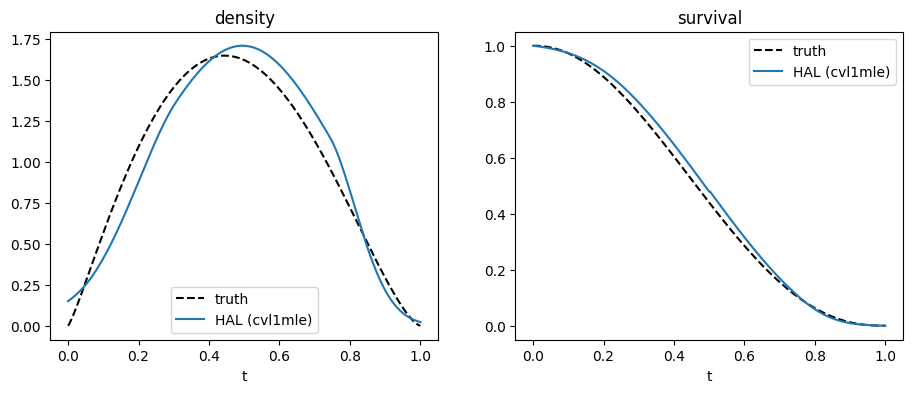

restricted mean survival time up to 0.8: 0.4830


In [3]:
fit = est.fit_at(0.4)
x = np.linspace(0, 1, 401)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(x, truth.pdf(x), "k--", label="truth")
axes[0].plot(x, fit.density(x), label="HAL (cvl1mle)")
axes[0].set_title("density")
axes[1].plot(x, truth.sf(x), "k--", label="truth")
axes[1].plot(x, fit.survival(x), label="HAL (cvl1mle)")
axes[1].set_title("survival")
for ax in axes:
    ax.set_xlabel("t")
    ax.legend()
plt.show()
print(f"restricted mean survival time up to 0.8: {fit.rmst(0.8)[0]:.4f}")

## The four methods side by side

All four take the same inputs and return the same summary. The second table gives the bound each method used,
divided by M1.

In [4]:
survival, factor = {}, {}
for method in METHODS:
    result = fit_right_censored(data, points, method=method, n_trials=20, random_state=0)
    survival[method] = result.summary.set_index("t0")["survival"]
    factor[method] = result.summary.set_index("t0")["norm_factor"]
display(pd.DataFrame(survival).assign(truth=truth.sf(points)).round(4))
pd.DataFrame(factor)

,ipcw_hal,l1mle_m1,cvl1mle,undersmoothed,truth
t0,,,,,
0.2,0.9106,0.9106,0.9106,0.9106,0.8887
0.4,0.6490,0.6489,0.6489,0.6489,0.6039
0.6,0.3144,0.3143,0.3143,0.3143,0.2853
0.8,0.0584,0.0583,0.0583,0.0583,0.0627


,ipcw_hal,l1mle_m1,cvl1mle,undersmoothed
t0,,,,
0.2,1.0,1.0,1.0,1.0
0.4,1.0,1.0,1.0,1.0
0.6,1.0,1.0,1.0,1.0
0.8,1.0,1.0,1.0,1.0


On this sample cross-validation over [M1, 2 M1] kept M1, so `"l1mle_m1"` and `"cvl1mle"` give the same fit,
and the undersmoothing rule kept M1 at every time point as well. On other samples the three differ.